# Online Retail — Full Data Analysis Project
### Pandas • Matplotlib • Seaborn • Plotly


**Dataset source:** [Online Retail Dataset — Kaggle](https://www.kaggle.com/datasets/vijayuv/onlineretail)

**Dataset facts:** The commonly distributed version contains approximately 541,909 transaction rows and fields such as invoice number, product code, description, quantity, invoice date, unit price, customer ID, and country. Your downloaded file may differ slightly, so always inspect it rather than assuming exact counts.



---

## 0. Environment setup and dataset loading

You can download the dataset through KaggleHub. If Kaggle authentication or package access is unavailable, download the dataset manually from the Kaggle page and update the file path below.

**Expected source file:** The original Online Retail dataset is commonly distributed as an Excel file (`.xlsx`). Your Kaggle copy may provide a CSV instead.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
sns.set_theme(style='whitegrid')
pd.set_option("display.max_columns", None)
data = pd.read_csv('OnlineRetail.csv', encoding='ISO-8859-1')
df = data.copy()

---

# Part 1 — Data Understanding & Initial Inspection (Questions 1–5)

### Q1. First look
Display the first 10 rows and last 10 rows. Based on the columns, explain what one row represents.

### Q2. Dataset dimensions
Find the number of rows and columns. Calculate the memory usage of the DataFrame and identify whether the dataset is large enough to require careful memory handling.

### Q3. Schema inspection
Display column names, data types, and non-null counts. Which columns have incorrect or unexpected data types?

### Q4. Statistical overview
Generate descriptive statistics for numeric and categorical columns separately. Write down at least three observations.

### Q5. Cardinality check
For each column, calculate the number of unique values. Identify columns that behave like identifiers and columns that represent categories.

In [2]:
count = df.nunique()
print(count)

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64


In [3]:
display(df.head(11))
display(df.tail(11))
rows, cols = df.shape
print("rows:", rows)
print("columns:", cols)
memory_usage = df.memory_usage(deep=True).sum()
print("Memory usage:", memory_usage)
memory_mb = memory_usage / (1024**2)
print("Memory usage: {:.2f}".format(memory_mb))
if memory_mb > 100:
    print("The dataset is large")
else:
    print("The dataset is manageable")
print(df.columns.tolist())
display(df.isna().sum())
display(df.info())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541898,581587,22727,ALARM CLOCK BAKELIKE RED,4,12/9/2011 12:50,3.75,12680.0,France
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,12/9/2011 12:50,3.75,12680.0,France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,12/9/2011 12:50,3.75,12680.0,France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,12/9/2011 12:50,1.95,12680.0,France
541902,581587,22629,SPACEBOY LUNCH BOX,12,12/9/2011 12:50,1.95,12680.0,France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,12/9/2011 12:50,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


rows: 541909
columns: 8
Memory usage: 70533849
Memory usage: 67.27
The dataset is manageable
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


None

In [4]:
display(df.describe().T)
display(df.describe(include='O').T)
#Top Country is United Kingdom
#Top Product sale is WHITE HANGING HEART T-LIGHT HOLDER
#There is 38 countries

,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


C:\Users\TUF\AppData\Local\Temp\ipykernel_19584\3328457042.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='O').T)


,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
InvoiceDate,541909,23260,10/31/2011 14:41,1114
Country,541909,38,United Kingdom,495478


---

# Part 2 — Data Quality Investigation (Questions 6–13)

### Q6. Missing values report
Calculate the missing-value count and missing-value percentage for every column. Sort the report by missing percentage.

### Q7. Missingness visualization
Create a visualization showing the distribution or pattern of missing values. Which columns are most affected?

### Q8. Duplicate investigation
Count fully duplicated rows. Display a sample of duplicates and investigate whether they are exact repeated records.

### Q9. Invoice and cancellation analysis
Inspect `InvoiceNo`. Identify cancellation invoices (commonly invoices whose number starts with `C`). Count them and calculate their share of all rows.

### Q10. Quantity validation
Investigate zero and negative values in `Quantity`. Are negative quantities necessarily errors? Explain how they may relate to returns or cancellations.

### Q11. Unit price validation
Investigate zero and negative values in `UnitPrice`. Count affected records and inspect examples before deciding how to handle them.

### Q12. Product description quality
Inspect missing and repeated values in `Description`. Identify whether product codes appear with multiple descriptions.

### Q13. Customer and country quality
Investigate missing `CustomerID` values and inspect the distribution of `Country`. Decide which analyses can be performed without customer IDs.

In [5]:
#َََQ6
missing_report = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing Percentage': round(df.isna().mean() * 100, 2)
}).sort_values(by='Missing Percentage', ascending=False)
print(missing_report)

             Missing Count  Missing Percentage
CustomerID          135080               24.93
Description           1454                0.27
StockCode                0                0.00
InvoiceNo                0                0.00
Quantity                 0                0.00
InvoiceDate              0                0.00
UnitPrice                0                0.00
Country                  0                0.00


In [6]:
#Q7
missing_per = (df.isnull().sum()/len(df)*100).sort_values(ascending=False).reset_index()
missing_per.columns = ['column','missing pers']
fig = px.bar(
    missing_per,
    x = 'column',
    y  = 'missing pers',
    color = 'missing pers',
    title= 'Missing Values Distribution'
)
fig.show()

In [7]:
#Q8
dup_count = df.duplicated().sum()
print('Count is :',dup_count)
Rows = df[df.duplicated(keep=False)]
display(Rows)
if dup_count > 0:
    print("The dataset contains duplicated rows ")
else:
    print("No fully duplicated rows")

Count is : 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,12/9/2011 11:34,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,12/9/2011 11:34,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,12/9/2011 11:34,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,12/9/2011 11:34,2.10,14446.0,United Kingdom


The dataset contains duplicated rows 


In [8]:
#Q9
cancelled_invoices = df[df['InvoiceNo'].astype(str).str.startswith('C')]
cancelled_count = len(cancelled_invoices)
cancelled_per = (cancelled_count / len(df)) * 100
print("Cancelled count:", cancelled_count)
print(f"Share of all rows: {cancelled_per:.2f}%")
display(cancelled_invoices)

Cancelled count: 9288
Share of all rows: 1.71%


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/2011 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/2011 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/2011 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/2011 11:58,1.25,17315.0,United Kingdom


In [9]:
#َQ10
zero_qty = df[df['Quantity'] == 0]
neg_qty = df[df['Quantity'] < 0]
print("Zero:", len(zero_qty))
print("Negative:", len(neg_qty))
print("Negative %:", round(len(neg_qty) / len(df) * 100, 2))
print(neg_qty['Quantity'].describe())
neg_qty.head()
# No zero quantities were found
# There are 10,624 negative quantities about 2% of rows 
# They are not necessarily errors, because negative quantities usually represent returns or cancellations that reverse an earlier sale
# I will keep them, but analyze them separately from normal sales

Zero: 0
Negative: 10624
Negative %: 1.96
count    10624.000000
mean       -45.607210
std       1092.214216
min     -80995.000000
25%        -10.000000
50%         -2.000000
75%         -1.000000
max         -1.000000
Name: Quantity, dtype: float64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom


In [10]:
#Q11
zero_price = df[df['UnitPrice'] == 0]
neg_price = df[df['UnitPrice'] < 0]
print("Zero:", len(zero_price))
print("Negative:", len(neg_price))
display(zero_price.head())
display(neg_price.head())

Zero: 2515
Negative: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


In [11]:
#Q12
diss_null = df['Description'].isnull().sum()
print("Missing:",diss_null)
diss_uni = df['Description'].nunique()
print("Unique:",diss_uni)
multi_stock = df.groupby('StockCode')['Description'].nunique()
print((multi_stock > 1).sum())
most_common = df.groupby('StockCode')['Description'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
df['Description'] = df['StockCode'].map(most_common)
display(most_common)

Missing: 1454
Unique: 4223
650


StockCode
10002                  INFLATABLE POLITICAL GLOBE 
10080                     GROOVY CACTUS INFLATABLE
10120                                 DOGGY RUBBER
10123C                       HEARTS WRAPPING TAPE 
10123G                                         NaN
                               ...                
gift_0001_20    Dotcomgiftshop Gift Voucher £20.00
gift_0001_30    Dotcomgiftshop Gift Voucher £30.00
gift_0001_40    Dotcomgiftshop Gift Voucher £40.00
gift_0001_50    Dotcomgiftshop Gift Voucher £50.00
m                                           Manual
Name: Description, Length: 4070, dtype: str

In [12]:
#Q13
print("Missing CustomerID:", df['CustomerID'].isna().sum())
print("Missing %:", round(df['CustomerID'].isna().mean() * 100, 2))
print(df['Country'].value_counts().head(10))
print("Countries:", df['Country'].nunique())

Missing CustomerID: 135080
Missing %: 24.93
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64
Countries: 38


---

# Part 3 — Data Cleaning & Feature Engineering (Questions 14–18)

### Q14. Define a cleaning strategy
Before changing the data, write a short plan. Explain how you will handle:
- Missing customer IDs and descriptions.
- Exact duplicate rows.
- Cancellation invoices.
- Negative quantities and zero/negative prices.
- Incorrect data types.

Do not delete returns or cancellations without explaining the analytical purpose.

### Q15. Apply cleaning steps
Create a separate DataFrame named `clean_df`. Apply your chosen cleaning strategy and document how many rows were removed or changed at each step.

### Q16. Convert data types
Ensure `InvoiceDate` is datetime and `CustomerID` is handled consistently. Convert other fields to appropriate types where justified.

### Q17. Create transaction revenue
Create a `Revenue` column using `Quantity * UnitPrice`. Explain how this calculation behaves for negative quantities and cancellation records.

### Q18. Create date features
Create `Year`, `Month`, `MonthName`, `DayName`, and `Hour` from `InvoiceDate`. Keep a chronological month order for later charts.

In [13]:
#Q14
#Remove rows with missing CustomerID for customer analysis
#Remove exact duplicate rows
#Keep cancellation invoices and returns because they are important for net sales analysis
#Keep negative quantities (returns), but remove records with zero or negative prices if they are invalid
#Convert columns to correct data types,

In [14]:
#َQ15
# Create a copy of the original DataFrame
clean_df = df.copy()
rows_before = len(clean_df)
clean_df = clean_df.dropna(subset=['CustomerID'])
print("Removed missing CustomerID:", rows_before - len(clean_df))
missing_desc = clean_df['Description'].isna().sum()
clean_df['Description'] = clean_df['Description'].fillna('Unknown')
print("Descriptions filled:", missing_desc)
rows_before = len(clean_df)
clean_df = clean_df.drop_duplicates()
print("Duplicate rows removed:", rows_before - len(clean_df))
rows_before = len(clean_df)
clean_df = clean_df[clean_df['UnitPrice'] > 0]
print("Invalid price rows removed:", rows_before - len(clean_df))
print("Final shape:", clean_df.shape)

Removed missing CustomerID: 135080
Descriptions filled: 0
Duplicate rows removed: 5227
Invalid price rows removed: 40
Final shape: (401562, 8)


In [15]:
#َQ16
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'],errors='coerce')
clean_df['CustomerID'] = clean_df['CustomerID'].astype('Int64')
clean_df['Quantity'] = pd.to_numeric(clean_df['Quantity'])
clean_df['UnitPrice'] = pd.to_numeric(clean_df['UnitPrice'])

In [16]:
#Q17
clean_df['Revenue'] = clean_df['Quantity'] * clean_df['UnitPrice']
clean_df.head(10)
#For returns or cancellation records with negative quantities
# the revenue becomes negative, which correctly reduces the total sales and reflects the value of returned items

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
8,536366,22632,HAND WARMER RED RETROSPOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047,United Kingdom,54.08


In [17]:
#Q18
clean_df['Year'] = clean_df['InvoiceDate'].dt.year
clean_df['Month'] = clean_df['InvoiceDate'].dt.month
clean_df['MonthName'] = clean_df['InvoiceDate'].dt.month_name()
clean_df['DayName'] = clean_df['InvoiceDate'].dt.day_name()
clean_df['Hour'] = clean_df['InvoiceDate'].dt.hour
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

clean_df['MonthName'] = pd.Categorical(
    clean_df['MonthName'],
    categories=month_order,
    ordered=True
)
clean_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,DayName,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,December,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,December,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8


In [18]:
#Q19
clean_df = clean_df[clean_df['Quantity'] > 0]
top_qty = (
    clean_df.groupby('Description', as_index=False)
    .agg(Total_Quantity=('Quantity', 'sum'))
    .sort_values('Total_Quantity', ascending=False)
    .head(10)
)
top_qty

,Description,Total_Quantity
2173,"PAPER CRAFT , LITTLE BIRDIE",80995
1861,MEDIUM CERAMIC TOP STORAGE JAR,77916
3565,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54319
2439,POPCORN HOLDER,49160
1652,JUMBO BAG RED RETROSPOT,46078
3480,WHITE HANGING HEART T-LIGHT HOLDER,36763
204,ASSORTED COLOUR BIRD ORNAMENT,35263
2125,PACK OF 72 RETROSPOT CAKE CASES,33670
2495,RABBIT NIGHT LIGHT,27153
1914,MINI PAINT SET VINTAGE,26076


---

# Part 4 — Pandas Business Analysis (Questions 19–24)

### Q19. Top products by quantity
Find the 10 products with the highest total quantity sold. Exclude or separately report returns so that sales and returns are not mixed.

### Q20. Top products by revenue
Find the 10 products with the highest total revenue. Compare the ranking with Q19. Are the same products at the top?

### Q21. Country performance
Calculate total revenue, number of invoices, and average invoice value for each country. Rank countries by revenue and compare the United Kingdom with other countries.

### Q22. Monthly revenue trend
Aggregate revenue by month and year. Which month has the highest revenue? Which month has the lowest? Use a chronological index.

### Q23. Customer analysis
Calculate total spend, number of invoices, and average spend per customer. Identify the top 10 customers by total spend. State how you handled missing CustomerID values.

### Q24. Invoice-level analysis
Group records by `InvoiceNo` to calculate invoice value, number of distinct products, and total quantity. Identify the largest invoices and investigate whether cancellations affect the ranking.

In [19]:
#َQ20
top_revenue = (
    clean_df.groupby('Description', as_index=False)
    .agg(Total_Revenue=('Revenue', 'sum'))
    .sort_values('Total_Revenue', ascending=False)
    .head(10)
)
top_revenue
#The rankings are different. Some products appear in both lists, but high\-revenue products are not always the highest in quantity because revenue is influenced by both sales volume and unit price.

,Description,Total_Revenue
2173,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2605,REGENCY CAKESTAND 3 TIER,142264.75
3480,WHITE HANGING HEART T-LIGHT HOLDER,100547.45
1652,JUMBO BAG RED RETROSPOT,85040.54
1861,MEDIUM CERAMIC TOP STORAGE JAR,81416.73
2450,POSTAGE,77803.96
2194,PARTY BUNTING,68785.23
204,ASSORTED COLOUR BIRD ORNAMENT,56413.03
1991,Manual,53419.93
2495,RABBIT NIGHT LIGHT,51251.24


In [20]:
#Q21
perf = (
    clean_df.groupby('Country', as_index=False)
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Number_Of_Invoices=('InvoiceNo', 'nunique'),
        Average_Invoice_Value=('Revenue', 'mean')
    )
    .sort_values('Total_Revenue', ascending=False)
)
perf

,Country,Total_Revenue,Number_Of_Invoices,Average_Invoice_Value
35,United Kingdom,7284472.794,16646,20.860401
23,Netherlands,285446.340,94,121.003111
10,EIRE,265262.460,260,36.709446
14,Germany,228678.400,457,25.338327
13,France,208934.310,389,25.094200
0,Australia,138453.810,57,117.234386
30,Spain,61558.560,90,24.832013
32,Switzerland,56443.950,51,30.659397
3,Belgium,41196.340,98,20.283772
31,Sweden,38367.830,36,85.261844


In [21]:
#Q22
monthly_revenue = (
    clean_df.groupby(['Year','Month'], as_index=False)
    .agg(Total_Revenue=('Revenue','sum'))
    .sort_values(['Year','Month'])
)
monthly_revenue

,Year,Month,Total_Revenue
0,2010,12,570422.730
1,2011,1,568101.310
2,2011,2,446084.920
3,2011,3,594081.760
4,2011,4,468374.331
5,2011,5,677340.300
6,2011,6,660046.050
7,2011,7,598962.901
8,2011,8,644051.040
9,2011,9,950690.202


In [22]:
#Q23
customer_analysis = (
    clean_df.groupby('CustomerID', as_index=False)
    .agg(
        Total_Spend=('Revenue', 'sum'),
        Number_of_Invoices=('InvoiceNo', 'nunique'),
        Average_Spend=('Revenue', 'mean')
    )
    .sort_values('Total_Spend', ascending=False)
)
top_10_customers = customer_analysis.head(10)
top_10_customers

,CustomerID,Total_Spend,Number_of_Invoices,Average_Spend
1689,14646,280206.02,73,134.973998
4201,18102,259657.30,60,602.453132
3728,17450,194390.79,46,578.544018
3008,16446,168472.50,2,56157.500000
1879,14911,143711.17,201,25.345885
55,12415,124914.53,21,174.950322
1333,14156,117210.08,55,84.021563
3771,17511,91062.38,31,94.561142
2702,16029,80850.84,63,335.480664
0,12346,77183.60,1,77183.600000


In [23]:
#Q24
invoice_analysis = (
    clean_df.groupby('InvoiceNo', as_index=False)
    .agg(
        Invoice_Value=('Revenue', 'sum'),
        Distinct_Products=('Description', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_values('Invoice_Value', ascending=False)
)
top_invoices = invoice_analysis.head(10)
top_invoices

,InvoiceNo,Invoice_Value,Distinct_Products,Total_Quantity
18499,581483,168469.60,1,80995
1909,541431,77183.60,1,74215
7925,556444,38970.00,1,60
12417,567423,31698.16,12,12572
8111,556917,22775.93,137,15049
14456,572209,22206.00,7,1920
12409,567381,22104.80,12,6760
10842,563614,21880.44,97,12196
5462,550461,21535.90,5,9014
14368,572035,20277.92,125,13392


In [24]:
no_cancel_df = clean_df[~clean_df['InvoiceNo'].astype(str).str.startswith('C')]
no_cancel_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,MonthName,DayName,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,December,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,December,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,December,Wednesday,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,10.20,2011,12,December,Friday,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60,2011,12,December,Friday,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011,12,December,Friday,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011,12,December,Friday,12


---

# Part 5 — Matplotlib Visualizations 

### Q25. Product revenue comparison
Create a horizontal bar chart for the top 10 products by revenue. Include a clear title, axis labels, readable product labels, and an appropriate figure size.

### Q26. Monthly sales trend
Create a line chart of monthly revenue. Add markers, grid lines, axis labels, and a title. Ensure the months are sorted chronologically and explain the main trend.

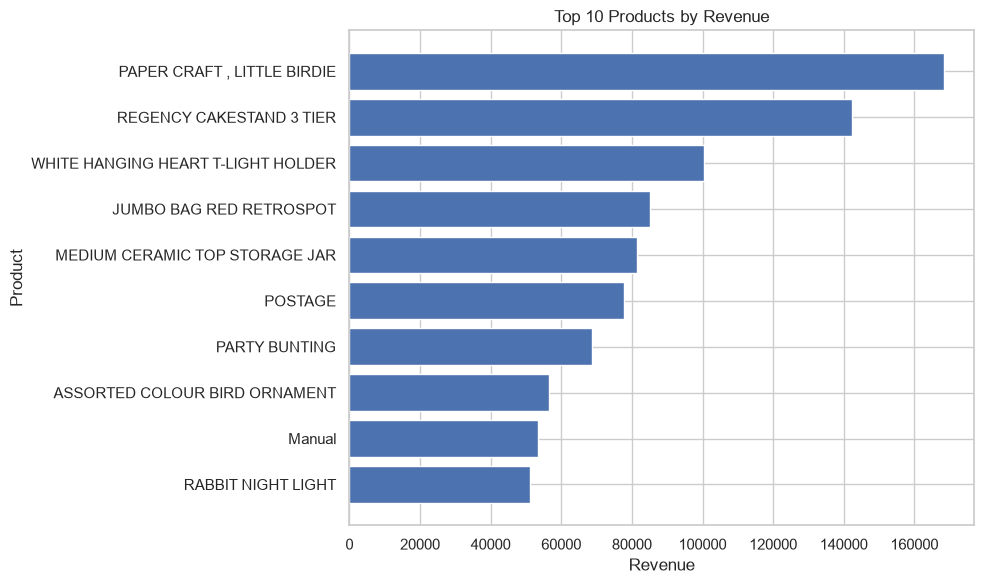

In [25]:
#Q25
top_revenue = (
    clean_df.groupby('Description', as_index=False)
    .agg(Total_Revenue=('Revenue', 'sum'))
    .sort_values('Total_Revenue', ascending=False)
    .head(10)
)
plt.figure(figsize=(10, 6))
plt.barh(top_revenue['Description'], top_revenue['Total_Revenue'])
plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

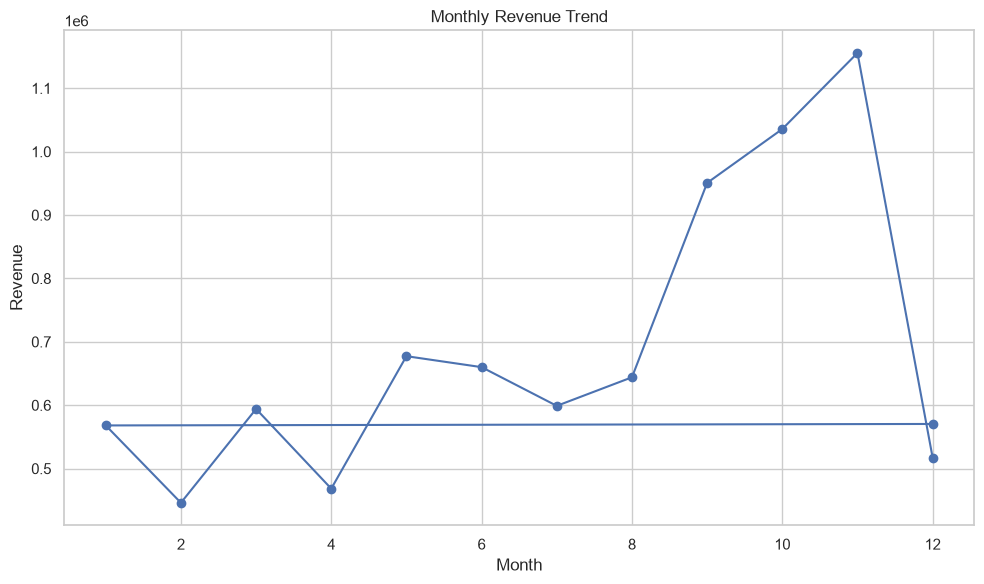

In [26]:
monthly_revenue = (
    clean_df.groupby(['Year', 'Month'], as_index=False)
    .agg(Total_Revenue=('Revenue', 'sum'))
    .sort_values(['Year', 'Month'])
)
plt.figure(figsize=(10, 6))
plt.plot(
    monthly_revenue['Month'],
    monthly_revenue['Total_Revenue'],
    marker='o'
)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.tight_layout()
plt.show()

---

# Part 6 — Seaborn Visualizations (Questions 27–28)

### Q27. Revenue distribution and outliers
Use a Seaborn boxplot to visualize the distribution of invoice values or transaction revenue. Handle extreme values thoughtfully: show the full distribution first, then optionally create a second view with a justified range. Explain what the outliers may represent.

### Q28. Correlation and final interactive dashboard chart
Choose suitable numeric features and create a Seaborn correlation heatmap with annotations. Then create at least one Plotly interactive chart (for example, monthly revenue by country or top products by revenue) with a meaningful hover tooltip. Write two insights from the visualizations.




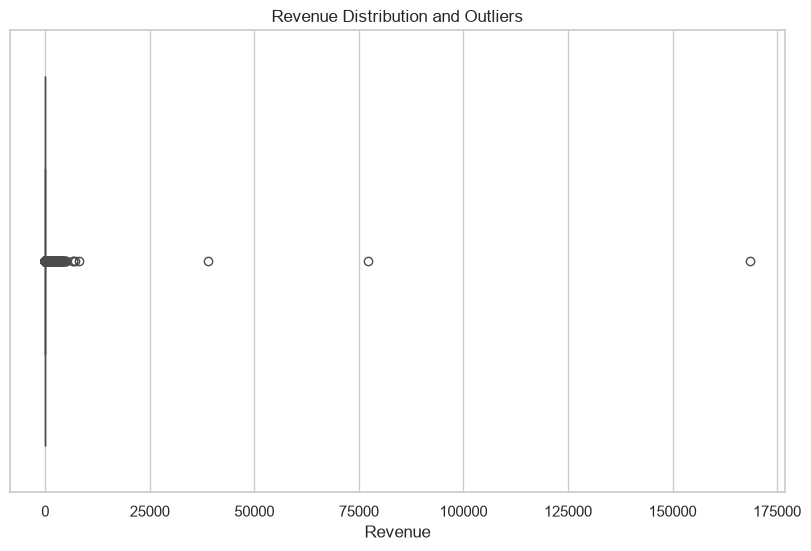

In [27]:
#Q27
plt.figure(figsize=(10, 6))
sns.boxplot(x=clean_df['Revenue'])
plt.title('Revenue Distribution and Outliers')
plt.xlabel('Revenue')
plt.show()

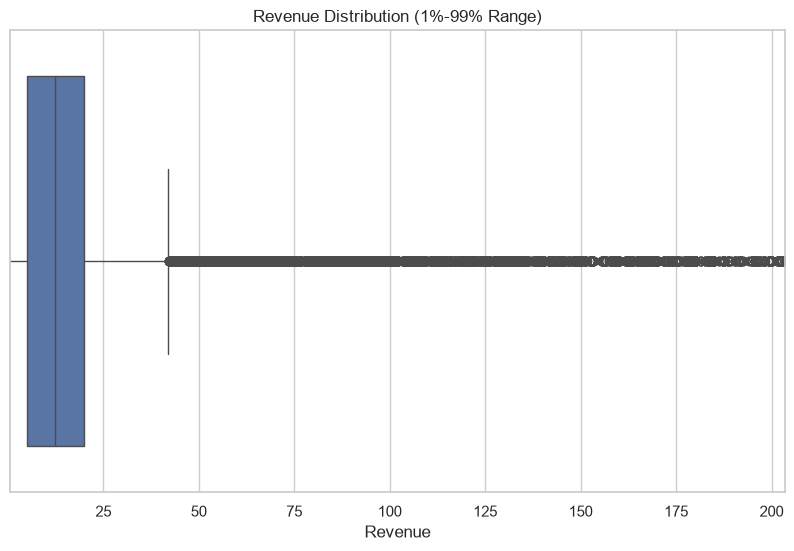

In [28]:
#Q27
plt.figure(figsize=(10, 6))
sns.boxplot(x=clean_df['Revenue'])
plt.xlim(
    clean_df['Revenue'].quantile(0.01),
    clean_df['Revenue'].quantile(0.99)
)
plt.title('Revenue Distribution (1%-99% Range)')
plt.xlabel('Revenue')
plt.show()

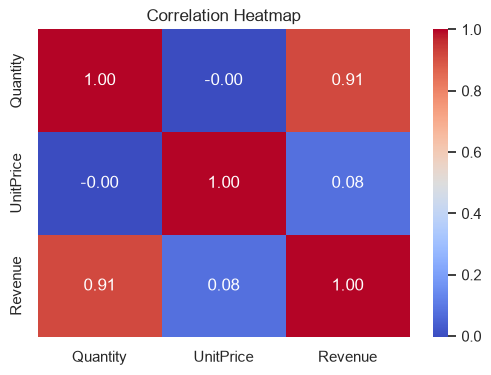

In [29]:
#Q28
corr = clean_df[['Quantity', 'UnitPrice', 'Revenue']].corr()
plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


## Final Project Conclusion

Write a concise conclusion containing:

1. The three most important data-quality issues you discovered.
2. The cleaning decisions you made and why.
3. The top product and top country by revenue.
4. One important trend in sales, customers, or returns.
5. Three actionable business recommendations.

## Publishing and Submission

- Restart the kernel and run all cells from top to bottom.
- Make sure your notebook contains no errors and all charts are visible.
- Publish the completed notebook publicly on Kaggle or GitHub.
- Publish a LinkedIn post describing your **3 most interesting findings** and include the notebook link.
- Submit both links: **Notebook URL** and **LinkedIn post URL**.


In [30]:
#During the data cleaning process, three major data\-quality issues were identified: missing CustomerID values, duplicate records, and invalid or inconsistent values such as negative quantities and prices. Missing CustomerID records were removed because they could not be linked to specific customers, duplicate rows were eliminated to avoid double counting, and data types were corrected to ensure accurate analysis. A Revenue column was created by multiplying Quantity by UnitPrice.

#The analysis showed that the highest revenue was generated by the top\-selling products, while the United Kingdom was the leading country in terms of total revenue. Monthly sales trends indicated that revenue varied across months, with certain periods showing stronger sales performance than others. Returns and cancellation transactions also had a noticeable impact on total revenue.#

#Based on these findings, three recommendations are suggested: focus marketing efforts on the highest\-revenue products, strengthen customer retention programs for top\-spending customers, and monitor return patterns to reduce cancellations and improve overall profitability.

